In [1]:
# # 05.1 — Propensity Score e Balanceamento
# **Pergunta:** Efeito causal da documentação clínica precoce (≤4h) sobre retorno 30d
# **Depende de:** gestante_enriquecido no DuckDB (executar 01_eda_gestante.py antes)
# **Salva em:** out/artifacts_causal/ e out/05.1_propensity/

In [2]:
from __future__ import annotations
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

ROOT       = Path("..").resolve()
OUT_DIR    = ROOT / "out" / "05.1_propensity"
ART_CAU_DIR = ROOT / "out" / "artifacts_causal"
OUT_DIR.mkdir(parents=True, exist_ok=True)
ART_CAU_DIR.mkdir(parents=True, exist_ok=True)

# ── Idioma / Language ─────────────────────────────────────────────────────────
LANG = "pt"  # "pt" | "en"  ← única linha a alterar para mudar idioma

_T = {
    "pt": {
        "ps_exp_lbl":       "Expostos (T=1)",
        "ps_ctrl_lbl":      "Controles (T=0)",
        "ps_xlabel":        "Propensity Score",
        "ps_ylabel":        "Densidade",
        "ps_title_fmt":     "Overlap PS — {label}",
        "love_pre_lbl":     "Pré-ponderação",
        "love_iptw_gbm":    "Pós-IPTW (GBM)",
        "love_iptw_log":    "Pós-IPTW (LogR)",
        "love_smd_lbl":     "SMD = 0.1",
        "love_xlabel":      "SMD",
        "love_title":       "Love Plot — Balanceamento IPTW (GBM vs LogR)",
    },
    "en": {
        "ps_exp_lbl":       "Treated (T=1)",
        "ps_ctrl_lbl":      "Controls (T=0)",
        "ps_xlabel":        "Propensity Score",
        "ps_ylabel":        "Density",
        "ps_title_fmt":     "PS Overlap — {label}",
        "love_pre_lbl":     "Pre-weighting",
        "love_iptw_gbm":    "Post-IPTW (GBM)",
        "love_iptw_log":    "Post-IPTW (LogR)",
        "love_smd_lbl":     "SMD = 0.1",
        "love_xlabel":      "SMD",
        "love_title":       "Love Plot — IPTW Balance (GBM vs LogR)",
    },
}
T = _T[LANG]

## 1. Carga dos Dados

In [3]:
import duckdb as _ddb

_DUCKDB        = ROOT / "data" / "gestante.duckdb"
_PARQUET_ENRIQ = ROOT / "data" / "gestante_quadro_clinico_enriquecido.parquet"

_tabs = _ddb.connect(str(_DUCKDB)).execute("SHOW TABLES").df()["name"].tolist()
if "gestante_enriquecido" in _tabs:
    _con = _ddb.connect(str(_DUCKDB))
    df = _con.execute("SELECT * FROM gestante_enriquecido").df()
    _con.close()
    df.columns = df.columns.str.lower()
    print(f"DuckDB gestante_enriquecido carregado: {len(df):,} registros")
elif _PARQUET_ENRIQ.exists():
    df = pd.read_parquet(_PARQUET_ENRIQ)
    df.columns = df.columns.str.lower()
    print(f"Parquet enriquecido carregado: {len(df):,} registros")
else:
    import sys; sys.path.insert(0, str(ROOT / "src"))
    from build_obstetric_features import enrich_obstetric
    df = pd.read_parquet(ROOT / "data" / "gestante_quadro_clinico.parquet")
    df.columns = df.columns.str.lower()
    df = df[df["is_recem_nascido"] == 0].copy()
    df = enrich_obstetric(df, llm_parquet=str(_DUCKDB))
    df = df[(df.flag_neonatal == 0)].copy()
    print(f"Processado do zero: {len(df):,} registros")

# ── Recomputar colunas datetime ────────────────────────────────────────────────
for c in ["dt_atendimento", "dt_alta", "dh_primeira_evolucao"]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

# ── Derivadas de dt_atendimento ────────────────────────────────────────────────
df["ano"]           = df["dt_atendimento"].dt.year
df["mes"]           = df["dt_atendimento"].dt.month
df["hora_admissao"] = df["dt_atendimento"].dt.hour

# ── Restaurar colunas com case misto (enriquecidas) ───────────────────────────
_MIXED_CASE_RESTORE = [
    "G_obs", "P_obs", "C_obs", "A_obs", "IG_obs", "N_obs",
    "grande_multipara_v2", "tem_aborto_v2", "tem_cesarea_v2", "primigesta",
    "risco_gestacao", "gestacao_gemelar", "gestacao_pretermo", "tipo_gestacao",
    "perfil_historico", "aborto_recorrente", "sem_filhos_vivos", "perda_previa",
    "perdas_nao_explicadas", "razao_perda",
]
_remap = {c.lower(): c for c in _MIXED_CASE_RESTORE
          if c.lower() in df.columns and c not in df.columns}
if _remap:
    df.rename(columns=_remap, inplace=True)

# ── Recomputar targets ─────────────────────────────────────────────────────────
df["y_retorno_30d"]    = (df["sn_retorno_30d"].fillna("N")  == "S").astype(int)
df["y_retorno_90d"]    = (df["sn_retorno_90d"].fillna("N")  == "S").astype(int) \
    if "sn_retorno_90d" in df.columns else 0
df["y_obito_materno"]  = (df["sn_obito_materno"].fillna("N") == "S").astype(int) \
    if "sn_obito_materno" in df.columns else 0
df["y_desfecho_grave"] = np.where(
    (df["y_obito_materno"] == 1) | (df["y_retorno_30d"] == 1), 1, 0
)

print(f"Colunas disponíveis: {list(df.columns)}")

## 2. Definição da Exposição e Coorte

In [4]:
# Exposição: evolução médica documentada nas primeiras 4 horas
df["horas_ate_1a_evolucao"] = (
    (df["dh_primeira_evolucao"] - df["dt_atendimento"])
    .dt.total_seconds() / 3600
)
df["T"] = (
    (df["qtd_evolucoes_documentadas"] > 0) &
    (df["horas_ate_1a_evolucao"] <= 4) &
    (df["horas_ate_1a_evolucao"] >= 0)
).astype(int)

# Outcome primário
df["Y"] = df["y_retorno_30d"]

# Features obstétricas derivadas
df["idade_anos"]   = pd.to_numeric(df.get("idade_anos"), errors="coerce")
ig_col = "IG_obs" if "IG_obs" in df.columns else "semanas_gestacao"
df["semanas_gest"] = pd.to_numeric(df[ig_col].fillna(df.get("semanas_gestacao", np.nan)),
                                   errors="coerce")

def seg_cid(c):
    if pd.isna(c): return "SEM_CID"
    c = str(c).upper()
    if c[:3] in [f"O{i:02d}" for i in range(10, 17)]: return "HIPERTENSIVOS"
    if c[:3] == "O24":                                  return "DIABETES_GEST"
    if c[:3] in ["O60", "O42", "O47"]:                  return "PARTO_PREMATURO"
    if c[0] == "O":                                      return "OUTROS_OBST"
    return "OUTROS"

df["segmento_cid"] = df["cd_cid"].apply(seg_cid)

# Manter apenas internações/urgências (exposição faz sentido somente nesses casos)
df = df[df["tp_atendimento"].isin(["I", "U"])].copy()

df_analise = df[
    df["dt_atendimento"].notna() &
    df["idade_anos"].notna()
].copy()

print(f"\nCoorte de análise : {len(df_analise):,}")
print(f"Expostos  (T=1)   : {df_analise['T'].sum():,}  ({df_analise['T'].mean()*100:.1f}%)")
print(f"Controles (T=0)   : {(1 - df_analise['T']).sum():,}")
print(f"Outcome   (Y=1)   : {df_analise['Y'].sum():,}  ({df_analise['Y'].mean()*100:.1f}%)")

# Coorte separada para 2ª pergunta causal (duração) — salva nos artefatos
df_dur = df[
    df["tp_atendimento"].isin(["I", "U"]) &
    df["duracao_horas_aprox"].notna() &
    df["duracao_horas_aprox"].between(1, 720) &
    df["dt_atendimento"].notna() &
    df["idade_anos"].notna()
].copy()
df_dur["T_doc"] = (df_dur["qtd_evolucoes_documentadas"].fillna(0) == 0).astype(int)
print(f"\nCoorte duração    : {len(df_dur):,}")

## 3. Confundidores e Pré-processamento

In [5]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

CONFUNDIDORES = [
    "idade_anos", "segmento_cid", "tp_atendimento",
    "semanas_gest", "qtd_diagnosticos", "qtd_pedidos_lab",
    "vl_escore_triagem", "duracao_horas_aprox",
    # Obstétricas enriquecidas
    "tipo_gestacao",
    "risco_gestacao",
    "gestacao_gemelar",
    "gestacao_pretermo",
    "G_obs",
    "grande_multipara_v2",
    "tem_aborto_v2",
    "perfil_historico",
    "perda_previa",
    "aborto_recorrente",
]
CONFUNDIDORES = [c for c in CONFUNDIDORES if c in df_analise.columns]

num_cols = [c for c in CONFUNDIDORES if pd.api.types.is_numeric_dtype(df_analise[c])]
cat_cols = [c for c in CONFUNDIDORES if c not in num_cols]

print(f"Confundidores numéricos : {num_cols}")
print(f"Confundidores categóricos: {cat_cols}")

# Pré-processamento: MICE para numéricos (mais robusto que mediana simples)
pre_ps = ColumnTransformer([
    ("num", Pipeline([
        ("imp", IterativeImputer(max_iter=10, random_state=42)),
        ("sc",  StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
], remainder="drop")

X_ps = pre_ps.fit_transform(df_analise[CONFUNDIDORES])
T    = df_analise["T"].values
Y    = df_analise["Y"].values

print(f"\nX_ps shape: {X_ps.shape}")

## 4. Análise de Positividade

In [6]:
print("\n" + "="*60)
print("ANÁLISE DE POSITIVIDADE")
print("="*60)

# Verificação via PS (antes do modelo — usa logística simples rápida)
from sklearn.linear_model import LogisticRegression as _LR_pos

_lr_pos = _LR_pos(C=1.0, max_iter=500, random_state=42)
_lr_pos.fit(X_ps, T)
_ps_raw = _lr_pos.predict_proba(X_ps)[:, 1]

pct_extreme_lo  = (_ps_raw < 0.05).mean() * 100
pct_extreme_hi  = (_ps_raw > 0.95).mean() * 100
pct_no_overlap  = ((_ps_raw < 0.05) | (_ps_raw > 0.95)).mean() * 100

print(f"\nPS preliminar (LogR) para diagnóstico de positividade:")
print(f"  PS < 0.05 (extremo baixo) : {pct_extreme_lo:.2f}%")
print(f"  PS > 0.95 (extremo alto)  : {pct_extreme_hi:.2f}%")
print(f"  Total sem overlap          : {pct_no_overlap:.2f}%")

# Verificação formal: para cada confounder categórico,
# checar se todas as combinações têm T=0 e T=1
pos_rows = []
for col in cat_cols:
    cats = df_analise[col].fillna("MISSING").unique()
    for cat in cats:
        sub = df_analise[df_analise[col].fillna("MISSING") == cat]
        n_t1 = sub["T"].sum()
        n_t0 = (1 - sub["T"]).sum()
        violates = (n_t1 == 0) or (n_t0 == 0)
        pos_rows.append({
            "variavel": col,
            "categoria": str(cat),
            "n_total": len(sub),
            "n_T1": int(n_t1),
            "n_T0": int(n_t0),
            "viola_positividade": int(violates),
        })

pos_df = pd.DataFrame(pos_rows)
n_viola = pos_df["viola_positividade"].sum()
print(f"\nVerificação formal de positividade (categóricas):")
print(f"  Categorias avaliadas        : {len(pos_df)}")
print(f"  Violações (só T=0 ou só T=1): {n_viola}")
if n_viola > 0:
    print("\n  Violações encontradas:")
    print(pos_df[pos_df["viola_positividade"] == 1].to_string(index=False))
else:
    print("  Nenhuma violação — positividade satisfeita para categorias observadas.")

pos_df.to_csv(OUT_DIR / "positivity_analysis.csv", index=False)
print(f"\n  Salvo: positivity_analysis.csv")

## 5. Propensity Score — Dois Modelos

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import brier_score_loss

# Modelo 1: Regressão Logística
lr_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr_model.fit(X_ps, T)
ps_logr_full = lr_model.predict_proba(X_ps)[:, 1]

# Modelo 2: Gradient Boosting
gbm_model = GradientBoostingClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42
)
gbm_model.fit(X_ps, T)
ps_gbm_full = gbm_model.predict_proba(X_ps)[:, 1]

# Avaliação cruzada
auroc_logr = cross_val_score(
    LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    X_ps, T, cv=5, scoring="roc_auc"
).mean()
auroc_gbm = cross_val_score(
    GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                learning_rate=0.05, random_state=42),
    X_ps, T, cv=5, scoring="roc_auc"
).mean()

brier_logr = brier_score_loss(T, ps_logr_full)
brier_gbm  = brier_score_loss(T, ps_gbm_full)

print("\n" + "="*55)
print("COMPARAÇÃO DE MODELOS DE PROPENSITY SCORE")
print("="*55)
print(f"{'Modelo':<20} {'AUROC (CV5)':<15} {'Brier Score':<15}")
print("-"*50)
print(f"{'LogisticRegression':<20} {auroc_logr:<15.4f} {brier_logr:<15.4f}")
print(f"{'GradientBoosting':<20} {auroc_gbm:<15.4f} {brier_gbm:<15.4f}")
print("-"*50)
print(f"\nPS primário: GBM  (melhor desempenho esperado)")
print(f"PS secundário: LogR (análise de sensibilidade)")

# Armazena em df_analise para uso posterior
df_analise["ps_gbm"]  = ps_gbm_full
df_analise["ps_logr"] = ps_logr_full

## 6. Overlap e Trimming

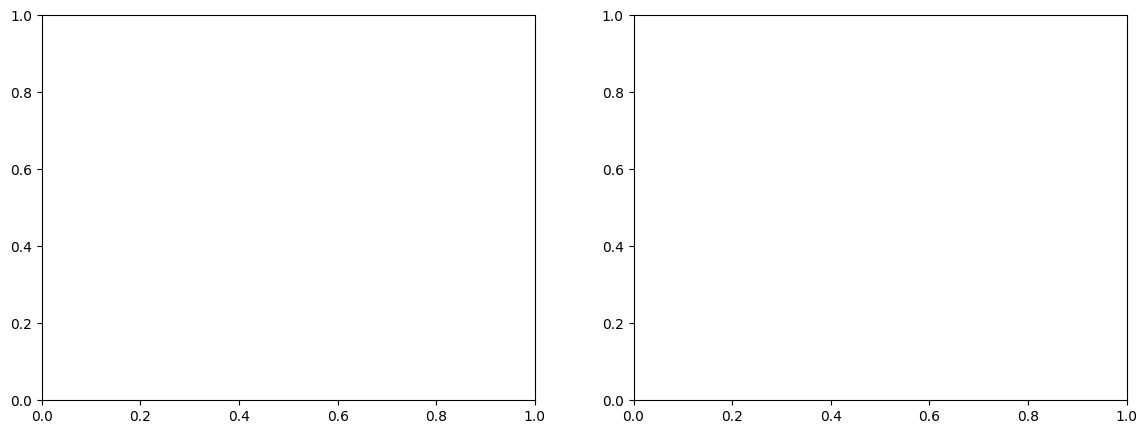

In [8]:
TRIM_LO, TRIM_HI = 0.05, 0.95

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, ps_vals, label in [
    (axes[0], ps_gbm_full,  "GBM"),
    (axes[1], ps_logr_full, "LogR"),
]:
    ax.hist(ps_vals[T == 1], bins=40, alpha=0.6, color="tomato",
            label=T["ps_exp_lbl"], density=True)
    ax.hist(ps_vals[T == 0], bins=40, alpha=0.6, color="steelblue",
            label=T["ps_ctrl_lbl"], density=True)
    ax.axvline(TRIM_LO, color="black", ls="--", lw=0.8, alpha=0.7)
    ax.axvline(TRIM_HI, color="black", ls="--", lw=0.8, alpha=0.7)
    ax.set_xlabel(T["ps_xlabel"])
    ax.set_ylabel(T["ps_ylabel"])
    ax.set_title(T["ps_title_fmt"].format(label=label))
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR / "overlap_ps.png", dpi=150)
plt.show()
plt.close()

# Trimming com PS primário (GBM)
mask_overlap = (ps_gbm_full >= TRIM_LO) & (ps_gbm_full <= TRIM_HI)
mask_overlap_logr = (ps_logr_full >= TRIM_LO) & (ps_logr_full <= TRIM_HI)

n_trim_gbm  = (~mask_overlap).sum()
n_trim_logr = (~mask_overlap_logr).sum()

print(f"\nTrimming [{TRIM_LO}, {TRIM_HI}]:")
print(f"  GBM  — {n_trim_gbm} obs. removidas  ({n_trim_gbm/len(T)*100:.2f}%)")
print(f"  LogR — {n_trim_logr} obs. removidas  ({n_trim_logr/len(T)*100:.2f}%)")

df_trim = df_analise[mask_overlap].copy()
ps_trim  = ps_gbm_full[mask_overlap]
T_trim   = T[mask_overlap]
Y_trim   = Y[mask_overlap]
X_ps_trim = X_ps[mask_overlap]

print(f"\nCoorte após trimming (GBM): {len(df_trim):,}")

## 7. IPTW e SMD Pré/Pós — Love Plot (Tabela 2 para o paper)

In [ ]:
eps = 1e-6

# Pesos IPTW estabilizados (ATE) com PS GBM
p_t_gbm    = T_trim.mean()
w_gbm_raw  = np.where(T_trim == 1,
                      p_t_gbm / (ps_trim + eps),
                      (1 - p_t_gbm) / (1 - ps_trim + eps))
w_clip     = np.clip(w_gbm_raw, 0, np.percentile(w_gbm_raw, 99))
df_trim["w_iptw"] = w_clip

# Pesos IPTW LogR (para a tabela de sensibilidade)
ps_logr_trim   = ps_logr_full[mask_overlap]
p_t_logr       = T_trim.mean()
w_logr_raw     = np.where(T_trim == 1,
                          p_t_logr / (ps_logr_trim + eps),
                          (1 - p_t_logr) / (1 - ps_logr_trim + eps))
w_logr_clip    = np.clip(w_logr_raw, 0, np.percentile(w_logr_raw, 99))
df_trim["w_iptw_logr"] = w_logr_clip


def weighted_mean(values, weights):
    w = np.asarray(weights, dtype=float)
    v = np.asarray(values, dtype=float)
    valid = ~np.isnan(v)
    if valid.sum() == 0:
        return np.nan
    return np.average(v[valid], weights=w[valid])


def smd_raw(df, col):
    g1 = pd.to_numeric(df[df["T"] == 1][col], errors="coerce").dropna()
    g0 = pd.to_numeric(df[df["T"] == 0][col], errors="coerce").dropna()
    if len(g1) == 0 or len(g0) == 0:
        return np.nan
    pooled = np.sqrt((g1.std() ** 2 + g0.std() ** 2) / 2)
    if pooled == 0:
        return 0.0
    return abs(g1.mean() - g0.mean()) / pooled


def smd_wtd(df, col, weight_col):
    g1 = df[df["T"] == 1].copy()
    g0 = df[df["T"] == 0].copy()
    v1 = pd.to_numeric(g1[col], errors="coerce")
    v0 = pd.to_numeric(g0[col], errors="coerce")
    pooled = np.sqrt(
        (pd.to_numeric(df[df["T"] == 1][col], errors="coerce").dropna().std() ** 2 +
         pd.to_numeric(df[df["T"] == 0][col], errors="coerce").dropna().std() ** 2) / 2
    )
    if pooled == 0:
        return 0.0
    m1 = weighted_mean(v1.values, g1[weight_col].values)
    m0 = weighted_mean(v0.values, g0[weight_col].values)
    if np.isnan(m1) or np.isnan(m0):
        return np.nan
    return abs(m1 - m0) / pooled


# SMD somente para numéricos presentes em df_trim
num_conf_trim = [c for c in CONFUNDIDORES
                 if pd.api.types.is_numeric_dtype(df_trim[c]) and c in df_trim.columns]

smd_pre_vals   = {c: smd_raw(df_trim, c) for c in num_conf_trim}
smd_post_gbm   = {c: smd_wtd(df_trim, c, "w_iptw")      for c in num_conf_trim}
smd_post_logr  = {c: smd_wtd(df_trim, c, "w_iptw_logr") for c in num_conf_trim}

# Estatísticas descritivas por grupo (para Tabela 2)
table2_rows = []
for col in num_conf_trim:
    v1 = pd.to_numeric(df_trim[df_trim["T"] == 1][col], errors="coerce")
    v0 = pd.to_numeric(df_trim[df_trim["T"] == 0][col], errors="coerce")
    table2_rows.append({
        "variavel":        col,
        "n_T1":            int(v1.notna().sum()),
        "mean_T1":         round(v1.mean(), 3),
        "n_T0":            int(v0.notna().sum()),
        "mean_T0":         round(v0.mean(), 3),
        "SMD_pre":         round(smd_pre_vals.get(col, np.nan), 4),
        "SMD_post_GBM":    round(smd_post_gbm.get(col, np.nan), 4),
        "SMD_post_LogR":   round(smd_post_logr.get(col, np.nan), 4),
        "desequilibrado":  int(smd_pre_vals.get(col, 0) > 0.1),
    })

table2_df = pd.DataFrame(table2_rows).sort_values("SMD_pre", ascending=False)

print("\n" + "="*80)
print("TABELA 2 — BALANCEAMENTO (para o paper)")
print("="*80)
print(table2_df.to_string(index=False))
print(f"\nVariáveis com SMD pré > 0.1: {table2_df['desequilibrado'].sum()}")
n_imb_gbm  = (table2_df["SMD_post_GBM"]  > 0.1).sum()
n_imb_logr = (table2_df["SMD_post_LogR"] > 0.1).sum()
print(f"Variáveis com SMD pós (GBM)  > 0.1: {n_imb_gbm}")
print(f"Variáveis com SMD pós (LogR) > 0.1: {n_imb_logr}")

table2_df.to_csv(OUT_DIR / "table2_balance.csv", index=False)

# Love plot com ambos os modelos
fig, ax = plt.subplots(figsize=(10, max(6, len(table2_df) * 0.4)))
y_idx = np.arange(len(table2_df))
h     = 0.25

labels = table2_df["variavel"].tolist()[::-1]

ax.barh(y_idx,         table2_df["SMD_pre"][::-1].values,      height=h,
        color="lightgray",  label=T["love_pre_lbl"],           align="center")
ax.barh(y_idx + h,     table2_df["SMD_post_GBM"][::-1].values, height=h,
        color="tomato",     label=T["love_iptw_gbm"],          align="center")
ax.barh(y_idx + 2 * h, table2_df["SMD_post_LogR"][::-1].values, height=h,
        color="steelblue",  label=T["love_iptw_log"],          align="center")

ax.axvline(0.1, color="black", ls="--", lw=0.8, label=T["love_smd_lbl"])
ax.set_yticks(y_idx + h)
ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel(T["love_xlabel"])
ax.set_title(T["love_title"])
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "love_plot.png", dpi=150)
plt.show()
plt.close()

## 8. Salvar Artefatos

In [ ]:
import pickle

with open(ART_CAU_DIR / "cohort.pkl", "wb") as f:
    pickle.dump({
        "df_trim":       df_trim,
        "df_analise":    df_analise,
        "X_ps":          X_ps,
        "X_ps_trim":     X_ps_trim,
        "T":             T,
        "Y":             Y,
        "T_trim":        T_trim,
        "Y_trim":        Y_trim,
        "ps_gbm":        ps_gbm_full,
        "ps_logr":       ps_logr_full,
        "ps_trim":       ps_trim,
        "ps_logr_trim":  ps_logr_trim,
        "mask_overlap":  mask_overlap,
        "w_iptw":        w_clip,
        "w_iptw_logr":   w_logr_clip,
        "CONFUNDIDORES": CONFUNDIDORES,
        "num_cols":      num_cols,
        "cat_cols":      cat_cols,
        "df_dur":        df_dur,
        "eps":           eps,
        "TRIM_LO":       TRIM_LO,
        "TRIM_HI":       TRIM_HI,
    }, f)

print(f"[05.1] Artefatos salvos em: {ART_CAU_DIR}")

## Resumo dos Outputs

In [ ]:
print("\n" + "="*60)
print("05.1 — OUTPUTS GERADOS")
print("="*60)
print(f"  out/05.1_propensity/")
print(f"    positivity_analysis.csv  — positividade por categoria")
print(f"    overlap_ps.png           — overlap GBM vs LogR lado a lado")
print(f"    table2_balance.csv       — Tabela 2 para o paper")
print(f"    love_plot.png            — Love plot (ambos os modelos)")
print(f"  out/artifacts_causal/")
print(f"    cohort.pkl               — artefatos para 05.2")
print("="*60)